# 01 — CottonGuard-AI Dataset Audit

**Purpose:** inspect the original cotton-leaf dataset, assess image quality, identify exact and near-duplicate images, and create leakage-resistant *candidate* data splits.

> Run this notebook from top to bottom. It does not train models and does not overwrite the existing production split files or trained checkpoints.

**Expected classes:** `bacterial_blight`, `curl_virus`, `fussarium_wilt`, `healthy`.

In [1]:
# Google Colab: mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## 1. Imports and configuration

In [2]:
from pathlib import Path
from collections import Counter, defaultdict
from itertools import combinations
import hashlib
import random
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display

# Project paths: adjust DATA_DIR if your dataset is stored elsewhere.
DATA_DIR = Path('/content/drive/MyDrive/cotton')
PROJECT_DIR = Path('/content/drive/MyDrive/CottonGuard-AI')
RESULTS_DIR = PROJECT_DIR / 'results'
AUDIT_RESULTS_DIR = RESULTS_DIR / 'audit_review'

IMAGE_EXTENSIONS = {'.jpg', '.jpeg', '.png', '.bmp', '.webp'}
EXPECTED_CLASSES = {
    'bacterial_blight', 'curl_virus', 'fussarium_wilt', 'healthy'
}
RANDOM_STATE = 42
PHASH_THRESHOLD = 2

if not DATA_DIR.exists():
    raise FileNotFoundError(f'Dataset directory not found: {DATA_DIR}')

AUDIT_RESULTS_DIR.mkdir(parents=True, exist_ok=True)

print('Dataset:', DATA_DIR)
print('Project:', PROJECT_DIR)
print('Audit outputs:', AUDIT_RESULTS_DIR)

Dataset: /content/drive/MyDrive/cotton
Project: /content/drive/MyDrive/CottonGuard-AI
Audit outputs: /content/drive/MyDrive/CottonGuard-AI/results/audit_review


## 2. Dataset inventory and class distribution

Total images: 1716
Classes found: ['bacterial_blight', 'curl_virus', 'fussarium_wilt', 'healthy']
Expected classes missing: []
Unexpected classes: []


,image_count,percentage
class,,
bacterial_blight,454,26.456876
curl_virus,417,24.300699
fussarium_wilt,419,24.417249
healthy,426,24.825175


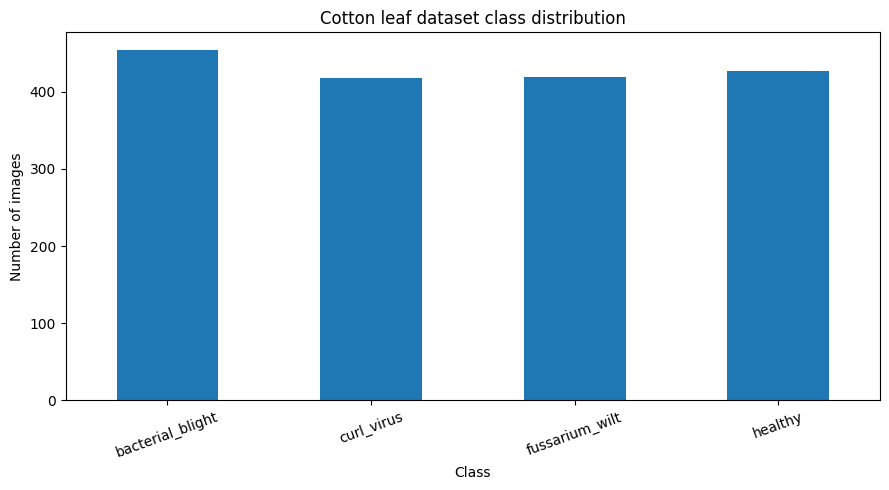

In [3]:
# Recursively collect supported image files.
image_files = sorted(
    p for p in DATA_DIR.rglob('*')
    if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
)

def get_class_name(path):
    # Dataset layout is expected to be DATA_DIR/class_name/image_file.
    relative = path.relative_to(DATA_DIR)
    if len(relative.parts) < 2:
        raise ValueError(f'Image is not inside a class folder: {path}')
    return relative.parts[0]

class_counts = Counter(get_class_name(p) for p in image_files)

print('Total images:', len(image_files))
print('Classes found:', sorted(class_counts))
print('Expected classes missing:', sorted(EXPECTED_CLASSES - set(class_counts)))
print('Unexpected classes:', sorted(set(class_counts) - EXPECTED_CLASSES))

class_distribution = (
    pd.Series(class_counts, name='image_count')
      .rename_axis('class')
      .sort_index()
      .to_frame()
)
class_distribution['percentage'] = (
    class_distribution['image_count'] / class_distribution['image_count'].sum() * 100
)
display(class_distribution)

ax = class_distribution['image_count'].plot(
    kind='bar', figsize=(9, 5), title='Cotton leaf dataset class distribution'
)
ax.set_xlabel('Class')
ax.set_ylabel('Number of images')
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

## 3. Visual inspection

In [4]:
# Display up to three reproducibly selected examples per class.
random.seed(RANDOM_STATE)
class_names = sorted(class_counts)
fig, axes = plt.subplots(len(class_names), 3, figsize=(12, 4 * len(class_names)))
axes = np.atleast_2d(axes)

for row, class_name in enumerate(class_names):
    paths = [p for p in image_files if get_class_name(p) == class_name]
    samples = random.sample(paths, min(3, len(paths)))
    for col, ax in enumerate(axes[row]):
        ax.axis('off')
        if col < len(samples):
            with Image.open(samples[col]) as img:
                ax.imshow(img.convert('RGB'))
            ax.set_title(class_name)

plt.suptitle('Representative cotton leaf images', fontsize=15)
plt.tight_layout()
plt.show()

Output hidden; open in https://colab.research.google.com to view.

## 4. Image integrity, dimensions, and formats

In [5]:
# Verify image files and collect basic metadata.
image_metadata = []
corrupted_images = []

for path in image_files:
    try:
        with Image.open(path) as img:
            img.verify()
        with Image.open(path) as img:
            width, height = img.size
            image_format = img.format
        image_metadata.append({
            'path': str(path), 'class': get_class_name(path),
            'width': width, 'height': height, 'format': image_format
        })
    except Exception as exc:
        corrupted_images.append({'path': str(path), 'error': str(exc)})

image_metadata_df = pd.DataFrame(image_metadata)
corrupted_df = pd.DataFrame(corrupted_images)

print('Valid images:', len(image_metadata_df))
print('Corrupted/unreadable images:', len(corrupted_df))
if not image_metadata_df.empty:
    display(image_metadata_df[['width', 'height']].describe())
    display(image_metadata_df['format'].value_counts().to_frame('count'))
if not corrupted_df.empty:
    display(corrupted_df.head(20))

image_metadata_df.to_csv(AUDIT_RESULTS_DIR / 'image_metadata.csv', index=False)
corrupted_df.to_csv(AUDIT_RESULTS_DIR / 'corrupted_images.csv', index=False)

Valid images: 1716
Corrupted/unreadable images: 0


,width,height
count,1716.000000,1716.000000
mean,450.728438,437.317016
std,337.197811,322.263302
min,83.000000,72.000000
25%,251.000000,250.000000
50%,366.000000,357.500000
75%,540.000000,533.750000
max,3872.000000,3872.000000


,count
format,
JPEG,1581
PNG,134
WEBP,1


## 5. Exact duplicate detection (SHA-256)

In [6]:
# SHA-256 identifies files with exactly identical byte content.
hash_groups = defaultdict(list)
unreadable_for_hash = []

for path in image_files:
    try:
        digest = hashlib.sha256(path.read_bytes()).hexdigest()
        hash_groups[digest].append(path)
    except OSError as exc:
        unreadable_for_hash.append({'path': str(path), 'error': str(exc)})

duplicate_groups = {
    digest: paths for digest, paths in hash_groups.items() if len(paths) > 1
}
total_hashed_images = sum(map(len, hash_groups.values()))
unique_image_contents = len(hash_groups)
redundant_copies = total_hashed_images - unique_image_contents

print('Successfully hashed images:', total_hashed_images)
print('Unique image contents:', unique_image_contents)
print('Exact duplicate groups:', len(duplicate_groups))
print('Redundant copies:', redundant_copies)
print('Unreadable during hashing:', len(unreadable_for_hash))

Successfully hashed images: 1716
Unique image contents: 1591
Exact duplicate groups: 118
Redundant copies: 125
Unreadable during hashing: 0


## 6. Cross-class exact duplicate review

In [7]:
# Do not silently resolve conflicting labels: record them for manual review.
cross_class_duplicates = []

for digest, paths in duplicate_groups.items():
    labels = sorted({get_class_name(p) for p in paths})
    if len(labels) > 1:
        cross_class_duplicates.append({
            'sha256': digest,
            'classes': labels,
            'files': [str(p) for p in paths]
        })

print('Exact-duplicate groups spanning multiple classes:',
      len(cross_class_duplicates))
display(pd.DataFrame(cross_class_duplicates).head(20))

Exact-duplicate groups spanning multiple classes: 0


""


## 7. Build an exact-deduplicated image index

In [8]:
# Keep one representative per exact-content group.
# Exclude cross-class duplicate groups pending manual label review.
records = []
review_groups = []

for digest, paths in hash_groups.items():
    labels = {get_class_name(p) for p in paths}
    if len(labels) > 1:
        review_groups.append({
            'sha256': digest, 'classes': sorted(labels),
            'files': [str(p) for p in paths]
        })
        continue

    representative = sorted(paths)[0]
    records.append({
        'path': str(representative),
        'label': get_class_name(representative),
        'sha256': digest,
        'copies_found': len(paths)
    })

clean_df = pd.DataFrame(records).reset_index(drop=True)
print('Images in exact-deduplicated index:', len(clean_df))
print('Groups held for cross-class review:', len(review_groups))
display(clean_df['label'].value_counts().sort_index().to_frame('count'))

clean_df.to_csv(AUDIT_RESULTS_DIR / 'deduplicated_image_index.csv', index=False)
pd.DataFrame(review_groups).to_json(
    AUDIT_RESULTS_DIR / 'cross_class_duplicates.json',
    orient='records', indent=2
)

Images in exact-deduplicated index: 1591
Groups held for cross-class review: 0


,count
label,
bacterial_blight,432
curl_virus,379
fussarium_wilt,395
healthy,385


## 8. Near-duplicate detection using perceptual hashing

Perceptual hashing can identify visually similar images even when they have been resized or recompressed. The Hamming-distance threshold is a heuristic, not proof that two images are duplicates.

The pairwise comparison below is quadratic in the number of images. It is suitable for this dataset scale but may take some time.

In [9]:
# Install once if ImageHash is not already available.
%pip -q install ImageHash

In [10]:
import imagehash

phashes = []
hash_errors = []

for path in clean_df['path']:
    try:
        with Image.open(path) as img:
            phashes.append(imagehash.phash(img.convert('RGB')))
    except Exception as exc:
        phashes.append(None)
        hash_errors.append({'path': path, 'error': str(exc)})

valid_indices = [i for i, value in enumerate(phashes) if value is not None]
print('Perceptual hashes generated:', len(valid_indices))
print('Hash failures:', len(hash_errors))

Perceptual hashes generated: 1591
Hash failures: 0


## 9. Form connected near-duplicate groups

In [11]:
# Union-find groups images connected by at least one pHash match.
# Transitive grouping means A~B and B~C can put A, B, C in one group.
parent = list(range(len(clean_df)))

def find(x):
    while parent[x] != x:
        parent[x] = parent[parent[x]]
        x = parent[x]
    return x

def union(a, b):
    root_a, root_b = find(a), find(b)
    if root_a != root_b:
        parent[root_b] = root_a

for position, i in enumerate(valid_indices):
    for j in valid_indices[position + 1:]:
        if (phashes[i] - phashes[j]) <= PHASH_THRESHOLD:
            union(i, j)

clean_df['group_id'] = [find(i) for i in range(len(clean_df))]
group_sizes = clean_df.groupby('group_id').size()

print('Unique connected groups:', clean_df['group_id'].nunique())
print('Groups with multiple images:', int((group_sizes > 1).sum()))
print('Largest group size:', int(group_sizes.max()) if len(group_sizes) else 0)
display(group_sizes.sort_values(ascending=False).head(15).to_frame('image_count'))

Unique connected groups: 966
Groups with multiple images: 449
Largest group size: 8


,image_count
group_id,
1263,8
1326,8
1281,8
1557,7
1576,7
1384,7
1240,5
1516,5
1294,4


## 10. Review near-duplicate groups with mixed labels

In [12]:
group_class_counts = clean_df.groupby('group_id')['label'].nunique()
mixed_label_groups = group_class_counts[group_class_counts > 1]
print('Near-duplicate groups containing multiple labels:', len(mixed_label_groups))

if len(mixed_label_groups):
    mixed_group_details = clean_df[
        clean_df['group_id'].isin(mixed_label_groups.index)
    ].sort_values('group_id')
    display(mixed_group_details[['path', 'label', 'group_id']].head(50))
else:
    print('No mixed-label groups detected at the selected pHash threshold.')

mixed_group_details = (
    clean_df[clean_df['group_id'].isin(mixed_label_groups.index)]
    if len(mixed_label_groups) else pd.DataFrame(columns=clean_df.columns)
)
mixed_group_details.to_csv(
    AUDIT_RESULTS_DIR / 'near_duplicate_mixed_label_groups.csv', index=False
)

Near-duplicate groups containing multiple labels: 0
No mixed-label groups detected at the selected pHash threshold.


## 11. Group-aware candidate train/validation/test split

This creates *candidate* splits only. The files are saved under `results/audit_review/` and do not overwrite the existing production split files used by the trained model.

`GroupShuffleSplit` prevents a group from crossing partitions, but it does not guarantee exact class stratification. Inspect the class distribution below.

In [13]:
from sklearn.model_selection import GroupShuffleSplit

# First reserve approximately 15% of groups for the test partition.
split1 = GroupShuffleSplit(
    n_splits=1, test_size=0.15, random_state=RANDOM_STATE
)
trainval_idx, test_idx = next(
    split1.split(clean_df, groups=clean_df['group_id'])
)
trainval_df = clean_df.iloc[trainval_idx].copy()
test_df_new = clean_df.iloc[test_idx].copy()

# Reserve 15% of the full dataset for validation:
# 0.15 / 0.85 of the remaining train+validation subset.
validation_fraction = 0.15 / 0.85
split2 = GroupShuffleSplit(
    n_splits=1, test_size=validation_fraction, random_state=RANDOM_STATE
)
train_idx, val_idx = next(
    split2.split(trainval_df, groups=trainval_df['group_id'])
)
train_df_new = trainval_df.iloc[train_idx].copy()
val_df_new = trainval_df.iloc[val_idx].copy()

for frame, split_name in [
    (train_df_new, 'train'),
    (val_df_new, 'validation'),
    (test_df_new, 'test')
]:
    frame['split'] = split_name

train_df_new.to_csv(AUDIT_RESULTS_DIR / 'train_grouped_candidate.csv', index=False)
val_df_new.to_csv(AUDIT_RESULTS_DIR / 'validation_grouped_candidate.csv', index=False)
test_df_new.to_csv(AUDIT_RESULTS_DIR / 'test_grouped_candidate.csv', index=False)

print('Train:', len(train_df_new))
print('Validation:', len(val_df_new))
print('Test:', len(test_df_new))

Train: 1116
Validation: 236
Test: 239


## 12. Verify group leakage and inspect split distribution

In [14]:
train_groups = set(train_df_new['group_id'])
val_groups = set(val_df_new['group_id'])
test_groups = set(test_df_new['group_id'])

overlaps = {
    'train_validation': train_groups & val_groups,
    'train_test': train_groups & test_groups,
    'validation_test': val_groups & test_groups
}
for name, overlap in overlaps.items():
    print(f'{name} overlap:', len(overlap))

assert all(len(value) == 0 for value in overlaps.values()),     'Group leakage detected between candidate splits.'

combined_splits = pd.concat(
    [train_df_new, val_df_new, test_df_new], ignore_index=True
)
display(pd.crosstab(combined_splits['split'], combined_splits['label']))
print('Total candidate images:', len(combined_splits))
print('Unique groups:', combined_splits['group_id'].nunique())
print('SUCCESS: no group IDs overlap between candidate splits.')

train_validation overlap: 0
train_test overlap: 0
validation_test overlap: 0


label,bacterial_blight,curl_virus,fussarium_wilt,healthy
split,,,,
test,48,55,64,72
train,317,269,280,250
validation,67,55,51,63


Total candidate images: 1591
Unique groups: 966
SUCCESS: no group IDs overlap between candidate splits.


## 13. Save final audit summary

In [15]:
audit_summary = {
    'original_image_files': len(image_files),
    'valid_images': len(image_metadata_df),
    'corrupted_images': len(corrupted_df),
    'unique_exact_contents': unique_image_contents,
    'exact_duplicate_groups': len(duplicate_groups),
    'redundant_exact_copies': redundant_copies,
    'cross_class_exact_duplicate_groups': len(cross_class_duplicates),
    'deduplicated_index_images': len(clean_df),
    'near_duplicate_connected_groups': int(clean_df['group_id'].nunique()),
    'near_duplicate_mixed_label_groups': int(len(mixed_label_groups)),
    'candidate_train_images': len(train_df_new),
    'candidate_validation_images': len(val_df_new),
    'candidate_test_images': len(test_df_new),
    'train_validation_group_overlap': len(overlaps['train_validation']),
    'train_test_group_overlap': len(overlaps['train_test']),
    'validation_test_group_overlap': len(overlaps['validation_test'])
}
summary_df = pd.DataFrame(
    audit_summary.items(), columns=['metric', 'value']
)
display(summary_df)
summary_df.to_csv(AUDIT_RESULTS_DIR / 'dataset_audit_summary.csv', index=False)
print('Audit outputs saved to:', AUDIT_RESULTS_DIR)

,metric,value
0,original_image_files,1716
1,valid_images,1716
2,corrupted_images,0
3,unique_exact_contents,1591
4,exact_duplicate_groups,118
5,redundant_exact_copies,125
6,cross_class_exact_duplicate_groups,0
7,deduplicated_index_images,1591
8,near_duplicate_connected_groups,966
9,near_duplicate_mixed_label_groups,0


Audit outputs saved to: /content/drive/MyDrive/CottonGuard-AI/results/audit_review


## Notes and limitations

- Exact duplicate detection is based on file bytes (SHA-256).
- Perceptual-hash similarity is heuristic; inspect mixed-label groups and large clusters.
- GroupShuffleSplit prevents group overlap but does not enforce stratified class proportions.
- Candidate splits are not automatically adopted by existing training/evaluation code.
- Do not replace the existing production splits or retrain the model until the candidate splits have been reviewed and compared.
